# 01 · Dataset audit and split

Run this notebook from the repository root. It validates the original Raptor Maps metadata and images, explores class balance, and writes a reproducible split manifest. No training or test-set model selection happens here.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from src.dataset import CLASSES, SEED, load_metadata, make_splits, save_manifest

assert Path('data/module_metadata.json').exists(), 'Run Jupyter from the repository root and add the dataset under data/'
frame = load_metadata()
print(f'Validated {len(frame):,} images across {frame.anomaly_class.nunique()} classes')
frame.head()

Validated 20,000 images across 12 classes


,image_id,image_filepath,anomaly_class,label,pixel_sha256,dhash
0,0,images/0.jpg,Offline-Module,8,de300d7ddb0e28236af1714561c8e699388c8a6e05ef2e...,d4e8e0ece0f4d8f8
1,1,images/1.jpg,Offline-Module,8,916f317eb85e139d74f7b2fb0fb22978a467be293f22ea...,e0e0e0e0c0c0e0c0
2,10,images/10.jpg,Offline-Module,8,e8ce45aa1a8cd6c6a2ae051f2de072e386307459747c7d...,e4f8b8ccbce8f8ec
3,100,images/100.jpg,Offline-Module,8,152c8647869e1c6a8e8ccdc2577489102440599b9fe5fb...,c0e0c0a0e0e0e0d0
4,1000,images/1000.jpg,Diode-Multi,4,9d8bfa0d87dd38fce349bd775007f115e3e974e37b05b9...,e0e0e0e0e0e0e0e0


## Class distribution

The percentage table and chart show how much each class contributes. Accuracy alone would hide weak performance on the smaller anomaly classes.

,count,percent
anomaly_class,,
Cell,1877,9.38
Cell-Multi,1288,6.44
Cracking,940,4.70
Diode,1499,7.50
Diode-Multi,175,0.88
Hot-Spot,249,1.25
Hot-Spot-Multi,246,1.23
No-Anomaly,10000,50.00
Offline-Module,827,4.14


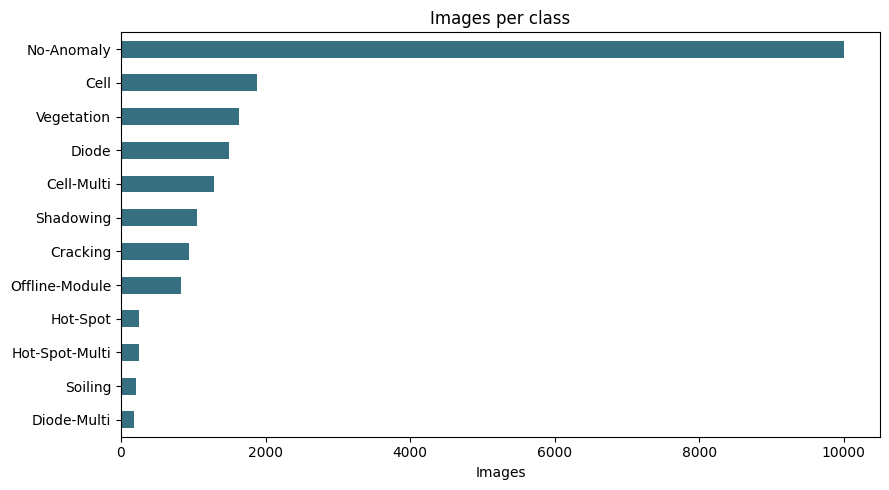

Largest / smallest class: 57.1×


In [2]:
distribution = frame.anomaly_class.value_counts().reindex(CLASSES).rename('count').to_frame()
distribution['percent'] = (100 * distribution['count'] / len(frame)).round(2)
display(distribution)
ax = distribution['count'].sort_values().plot.barh(figsize=(9, 5), color='#366f80')
ax.set(xlabel='Images', ylabel='', title='Images per class')
plt.tight_layout()
plt.show()
print(f'Largest / smallest class: {distribution["count"].max() / distribution["count"].min():.1f}×')

## One original image per class

These are grayscale JPEG renderings. Pixel intensity is not an absolute temperature.

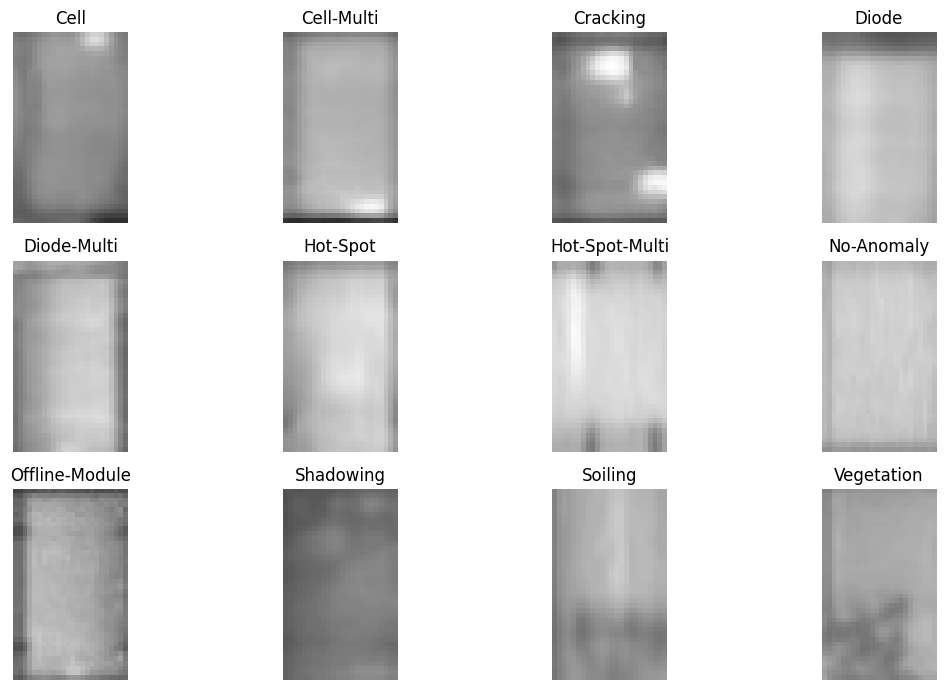

In [3]:
samples = frame.groupby('anomaly_class', sort=False).sample(n=1, random_state=SEED).set_index('anomaly_class')
fig, axes = plt.subplots(3, 4, figsize=(12, 7))
for ax, label in zip(axes.flat, CLASSES):
    with Image.open(Path('data') / samples.loc[label, 'image_filepath']) as image:
        ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    ax.set_title(label)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Exact and perceptual duplicate checks

Images with identical decoded pixels share a SHA-256 hash. Conflicting labels within a hash group are excluded from every experiment split. A 64-bit difference hash (dHash) flags visually similar candidates, but matching hashes do not prove the images are duplicates. The metadata has no site or session identifier.

In [4]:
duplicate_sizes = frame.groupby('pixel_sha256').size()
conflicts = frame.groupby('pixel_sha256').anomaly_class.nunique()
print(f'Exact duplicate groups: {(duplicate_sizes > 1).sum():,}')
print(f'Additional copies: {(duplicate_sizes - 1).clip(lower=0).sum():,}')
print(f'Conflicting-label groups: {(conflicts > 1).sum():,}')
print(f'Images excluded for conflicting labels: {frame.pixel_sha256.isin(conflicts.index[conflicts > 1]).sum():,}')
print(f'dHash candidate groups: {(frame.groupby("dhash").size() > 1).sum():,}')

Exact duplicate groups: 22
Additional copies: 22
Conflicting-label groups: 6
Images excluded for conflicting labels: 12
dHash candidate groups: 641


## Reproducible 70/15/15 split

The split is stratified by class at the exact-duplicate group level with seed 42. Groups with conflicting labels are marked `excluded`; only eligible images contribute to the target percentages. Duplicate group sizes can create small deviations.

In [5]:
manifest = make_splits(frame, seed=SEED)
path = save_manifest(manifest)
counts = manifest.groupby(['anomaly_class', 'split']).size().unstack(fill_value=0).reindex(CLASSES)
display(counts.assign(total=counts.sum(axis=1)))
print(manifest.split.value_counts().to_string())
print(f'Saved {path}')

split,excluded,test,train,val,total
anomaly_class,,,,,
Cell,1,282,1313,281,1877
Cell-Multi,2,193,900,193,1288
Cracking,3,140,656,141,940
Diode,1,225,1049,224,1499
Diode-Multi,0,27,122,26,175
Hot-Spot,1,37,174,37,249
Hot-Spot-Multi,0,37,172,37,246
No-Anomaly,0,1500,7000,1500,10000
Offline-Module,4,124,576,123,827


split
train       13992
test         2998
val          2998
excluded       12
Saved results\metrics\split_manifest.csv


In [6]:
assert manifest.image_id.is_unique
assert manifest.groupby('pixel_sha256').split.nunique().eq(1).all()
assert {'train', 'val', 'test'}.issubset(set(manifest.split))
assert pd.read_csv(path, dtype={'image_id': str, 'dhash': str}).equals(manifest)
print('ID overlap: none; exact duplicate leakage: none; saved manifest matches in-memory split.')
print(f'dHash candidate groups crossing splits: {(manifest.groupby("dhash").split.nunique() > 1).sum():,}')

ID overlap: none; exact duplicate leakage: none; saved manifest matches in-memory split.
dHash candidate groups crossing splits: 397


## Interpretation

Use validation data for model choice and leave test data untouched until final evaluation. Small classes and missing acquisition groups remain the main risks. Cross-split dHash matches are only candidates; inspect their images before treating the split as independent at the site level.